In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectFromModel
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, average_precision_score
from sklearn.metrics import classification_report,confusion_matrix,ConfusionMatrixDisplay,accuracy_score
from imblearn.over_sampling import SMOTE


# I. KHAI PHÁ (EDA) VÀ TIỀN XỬ LÝ DỮ LIỆU

## 1.1. Khai phá dữ liệu (EDA)

In [ ]:
# Tổng quan dữ liệu: describe, info
# Kiểm tra dữ liệu: missing, duplicate
# Vissualization để trực quan hơn
# Bảng thống kê mô tả (mean, median, std, min, max) các feature numeric
# Histogram phân phối từng feature numeric
# Boxplot từng feature numeric
# Bar chart tần suất từng feature categorical
# Biểu đồ phân phối target y (yes/no)

#-------------------------------------------------------------------------------------------------#
#import dữ liệu
df=pd.read_csv("bank-full.csv",sep=";")
df.info()
df.describe()

#tinh so mising trong du lieu
missing_count= df.isnull().sum()
#phan tram trong trong du lieu
missing_rate= 100 * df.isnull().mean() 
#trùng lặp dữ liệu
duplicated = df.duplicated().sum()

#total trong trong du lieu
total_missing = df.isnull().sum().sum()
total_value = df.shape[0]*df.shape[1]

missing_rate_total= 100*(total_missing/total_value)

print("So missing tung thanh phan la: \n",missing_count)
print("\n Ty le missing la: \n",missing_rate)
print ("\n Tong so missing cua data:\n", missing_rate_total)
print ("\n Tong so duplicated cua data:\n", duplicated)

#Thông tin trong côt dữ liệu y 
print(df['y'].value_counts())
print(df['y'].value_counts(normalize=True) * 100)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB
So missing tung thanh phan la: 
 age          0
job          0
marital      0
education    0
defaul

**Nhận xét**
* Dữ liệu có khoảng 45.000 dòng, với 16 cột dữ liệu (bao gồm 1 cột "y" dự đoán) và 2 loại kiểu chính là int và object
* Tỷ lệ duplicate và missing là 0% => Không cần điền khuyết và lọc bỏ trùng lặp
* Tuy nhiên, cột "y" có tỷ lệ "yes" chỉ khoảng 12% trong khi tỉ lệ "no" đạt khoảng 88% => mất cân bằng nghiêm trọng, cần xử lý trước khi huấn luyện
  

------------------------Chỉ số thống kê của các featrue------------------------
              age        balance        day     duration   campaign  \
mean    40.936210    1362.272058  15.806419   258.163080   2.763841   
median  39.000000     448.000000  16.000000   180.000000   2.000000   
std     10.618762    3044.765829   8.322476   257.527812   3.098021   
min     18.000000   -8019.000000   1.000000     0.000000   1.000000   
max     95.000000  102127.000000  31.000000  4918.000000  63.000000   

             pdays    previous  
mean     40.197828    0.580323  
median   -1.000000    0.000000  
std     100.128746    2.303441  
min      -1.000000    0.000000  
max     871.000000  275.000000  
------------------------Historgram của các feature------------------------


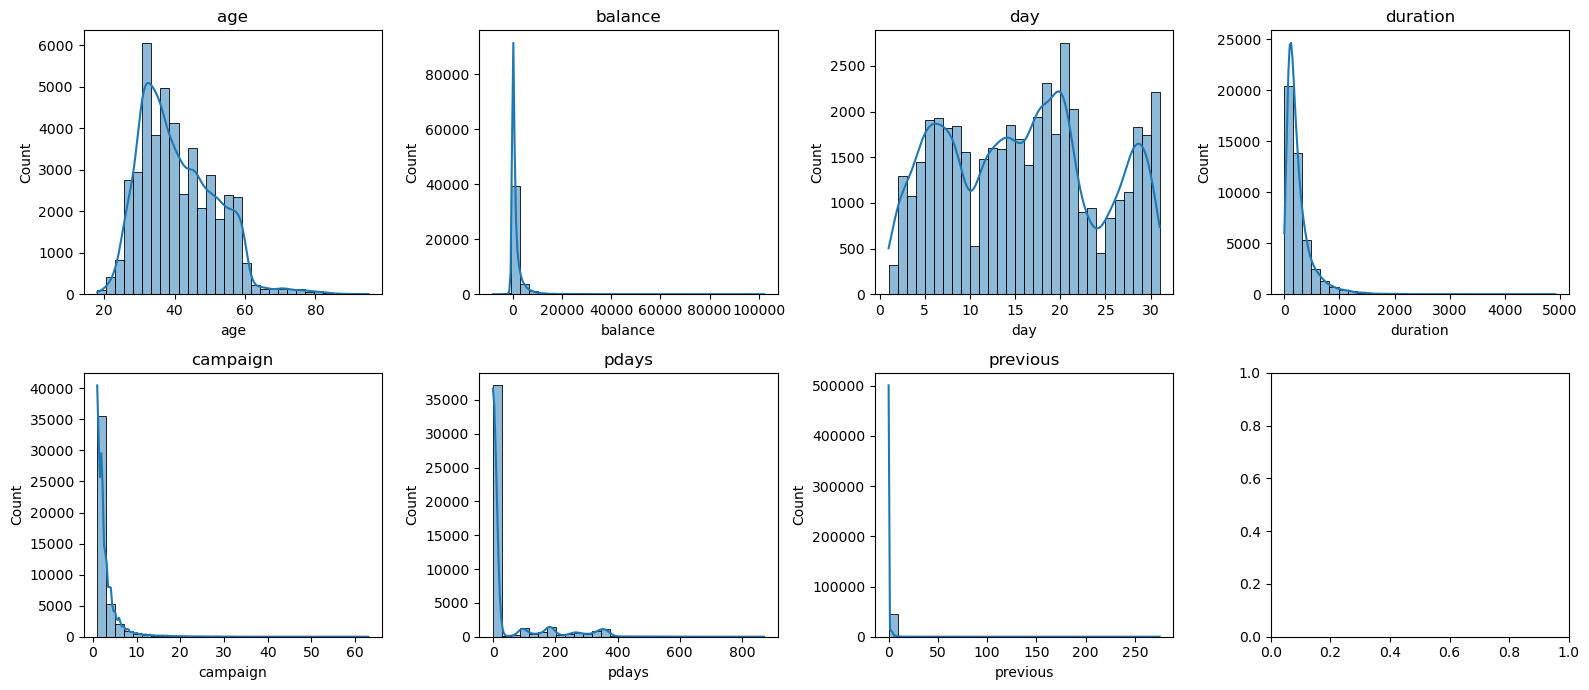

------------------------Boxplot của các feature------------------------


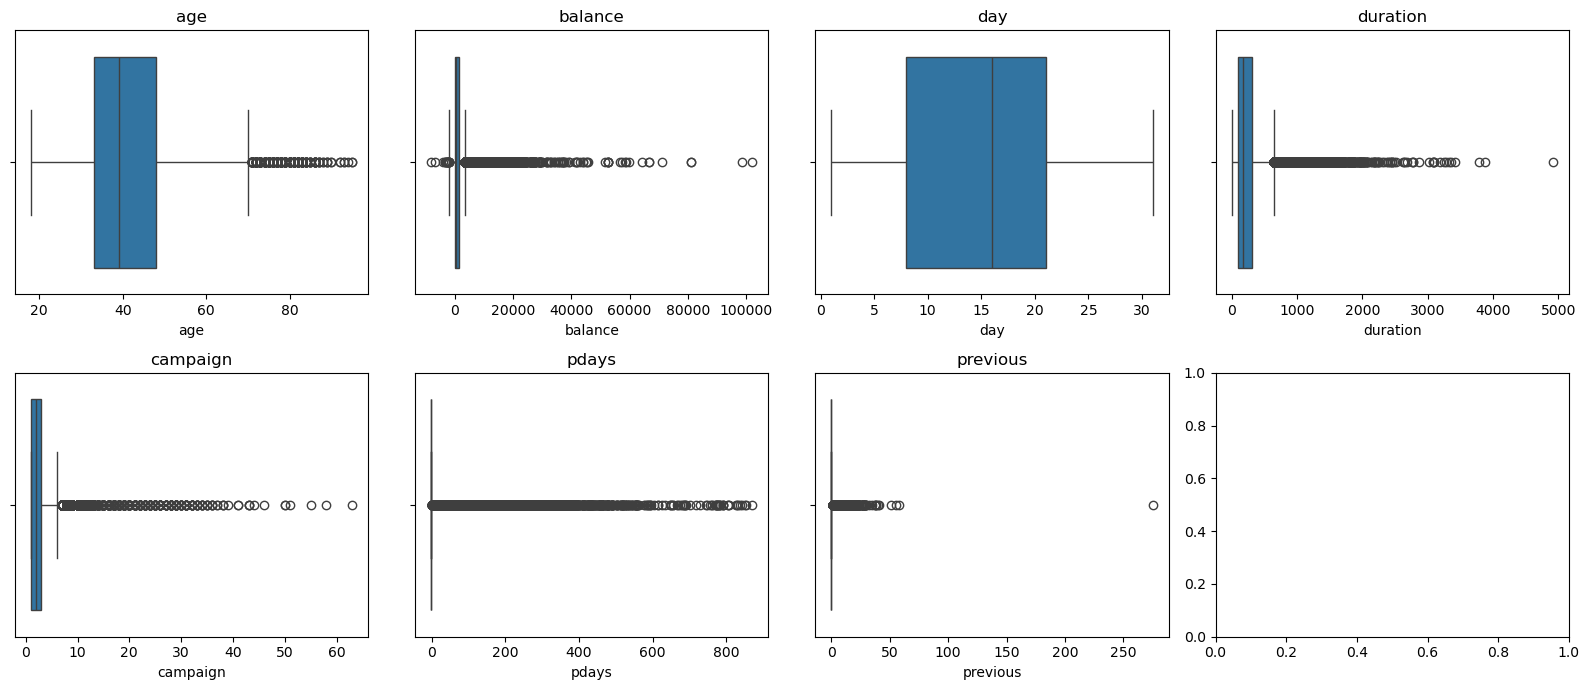

------------------------Historgram của các categorical------------------------


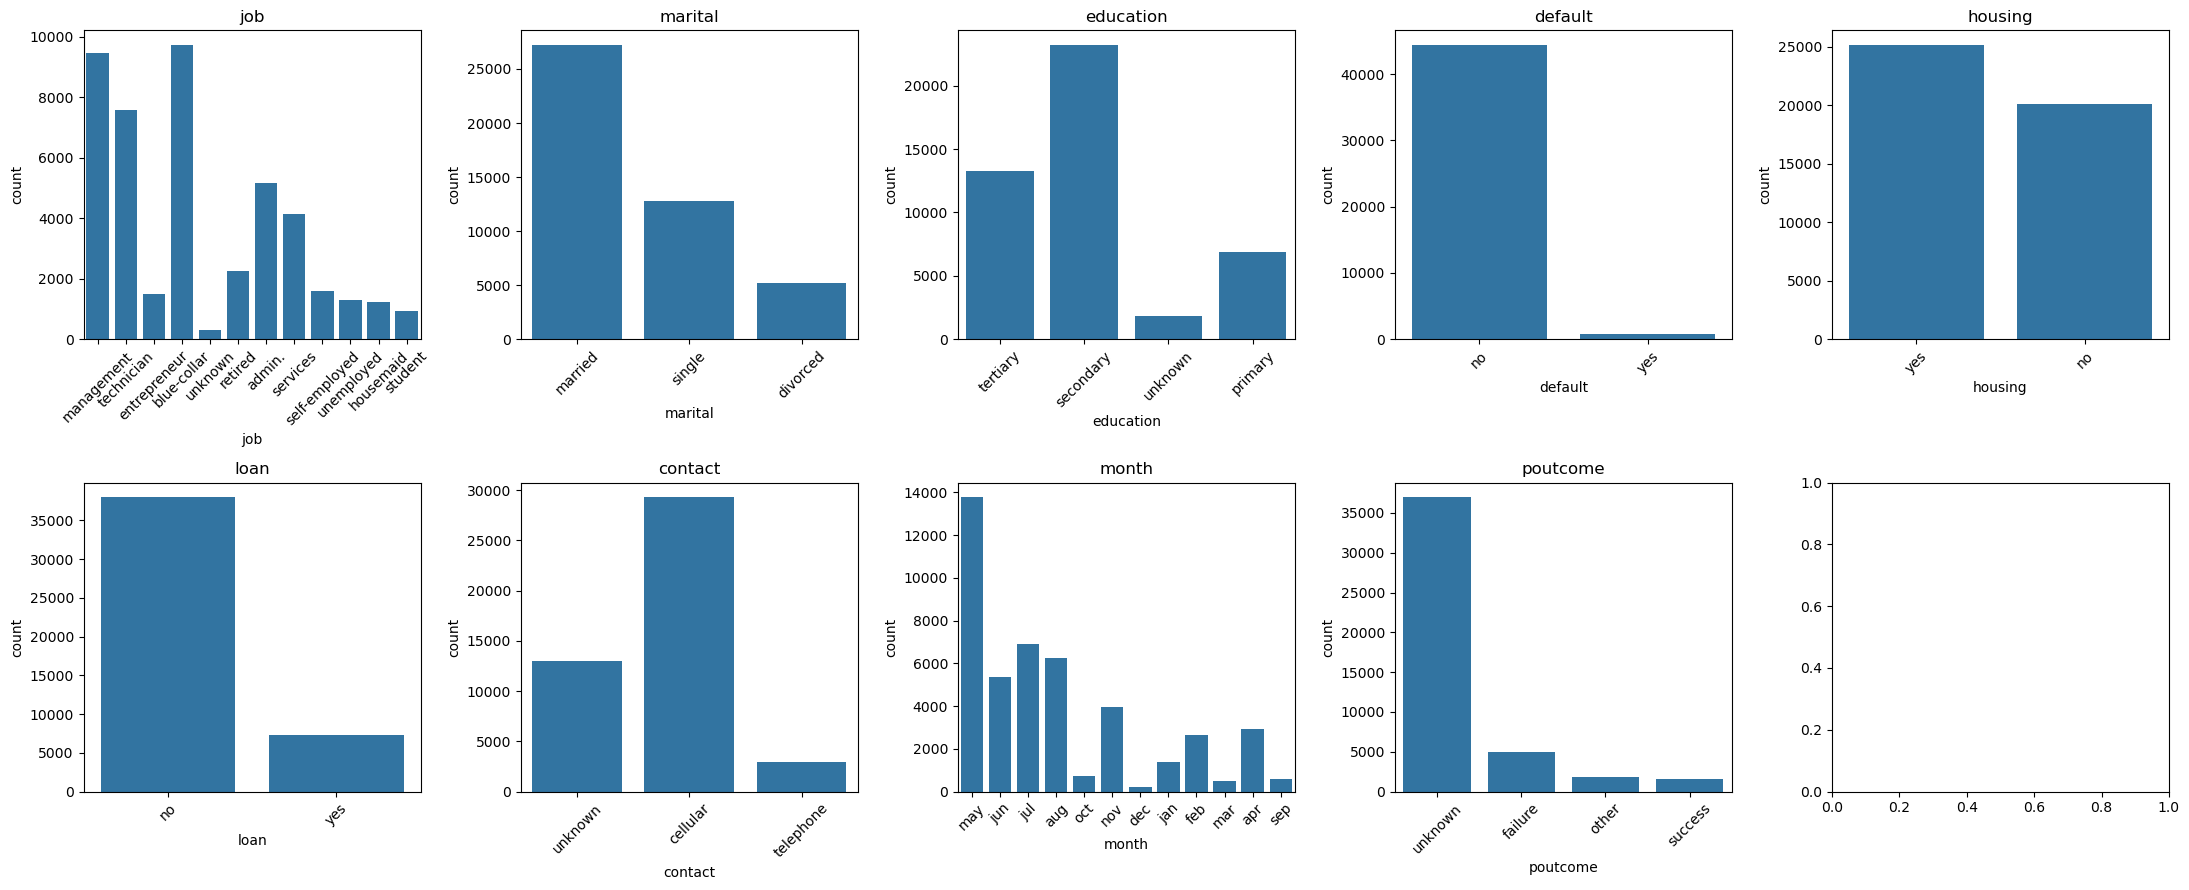

------------------------Historgram của các 'y'------------------------


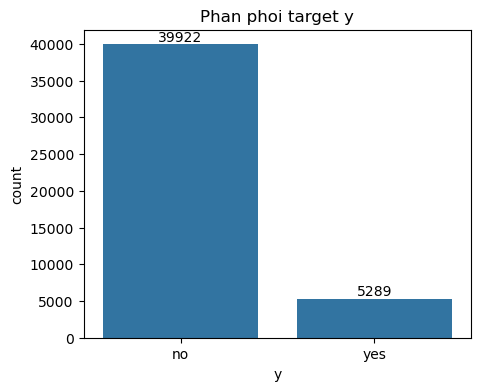

In [ ]:
#Visuallization
num_cols= df.select_dtypes(include=np.number).columns.tolist()
cat_cols= df.select_dtypes(exclude=np.number).columns.drop("y").tolist() #cat=categorical

#Hiển thị thông tin về thống kê của số
print("------------------------Chỉ số thống kê của các featrue------------------------")
statstic = df[num_cols].agg(["mean","median","std","min","max"])
print(statstic)

#Historgram của các feature
print("------------------------Historgram của các feature------------------------")
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
axes = axes.flatten()

for i, c in enumerate(num_cols):
    sns.histplot(df[c], bins=30, kde=True, ax=axes[i])
    axes[i].set_title(c)

plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
axes = axes.flatten()

#Boxplot của các feature
print("------------------------Boxplot của các feature------------------------")
for i, c in enumerate(num_cols):
    sns.boxplot(x=df[c], ax=axes[i])
    axes[i].set_title(c)

plt.tight_layout()
plt.show()

#categorical
print("------------------------Historgram của các categorical------------------------")
fig, axes = plt.subplots(2, 5, figsize=(22, 9))
axes = axes.flatten()

for i, c in enumerate(cat_cols):
    sns.countplot(data=df, x=c, ax=axes[i])
    axes[i].set_title(c)
    axes[i].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

#Phân phối của y
print("------------------------Historgram của các 'y'------------------------")
plt.figure(figsize=(5, 4))
ax = sns.countplot(data=df, x='y')
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center', va='bottom')
plt.title("Phan phoi target y")
plt.show()

**Nhận xét**
* Hầu hết các cột dữ liệu bị lệch phải
* Phạm vi về độ lớn dữ liệu khác nhau => thực hiện scaling cho tiền xử lý
* Có giá trị âm ở cột balance và pday, tuy nhiên nó hợp lý do mang ý nghĩa là nợ xấu và chưa được gọi điện
* Cột duration-thời gian gọi điện, nếu 0 thì chắc chắn 'no' => Chủ tập dataset khuyên bỏ do vấn đề data leakage

## 1.2. Tiền xử lý dữ liệu

### 1.2.1 Data Cleaning

In [ ]:
# Bảng số lượng outlier bị loại theo từng cột
# Boxplot so sánh trước/sau xử lý outlier
# Bảng xử lý missing/unknown (cột nào, phương pháp nào)
# Số liệu tổng số dòng trước/sau cleaning

NUMERIC_COLS = ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']
IQR_COLS = ['age', 'balance', 'campaign', 'pdays', 'previous']


def prepare_cleaning(data):
    """Sửa định dạng và đánh dấu giá trị số không hợp lệ là NaN."""
    result = data.copy(deep=True)
    result.columns = result.columns.str.strip()
    if result.columns.duplicated().any():
        raise ValueError('Tên cột bị trùng sau khi bỏ khoảng trắng.')
    required = NUMERIC_COLS + ['y']
    absent = [col for col in required if col not in result.columns]
    if absent:
        raise ValueError(f'Thiếu cột của bản Bank Marketing 16 features: {absent}')
    categorical = result.select_dtypes(include=['object', 'string']).columns
    for col in categorical:
        if col not in NUMERIC_COLS:
            result[col] = result[col].astype('string').str.strip().str.lower()
            result[col] = result[col].replace('', pd.NA)
    invalid_counts = {}
    for col in NUMERIC_COLS:
        original = result[col]
        values = pd.to_numeric(original, errors='coerce')
        invalid = original.notna() & values.isna()
        invalid = invalid | (values.notna() & ~np.isfinite(values))
        # Các cột numeric trong bản gốc đều chứa số nguyên.
        invalid = invalid | (values.notna() & (values % 1 != 0))
        if col == 'age':
            invalid = invalid | (values <= 0)
        elif col == 'campaign':
            invalid = invalid | (values < 1)
        elif col in ['duration', 'previous']:
            invalid = invalid | (values < 0)
        elif col == 'pdays':
            invalid = invalid | (values < -1)
        elif col == 'day':
            invalid = invalid | (values < 1) | (values > 31)
        invalid_counts[col] = int(invalid.sum())
        result[col] = values.mask(invalid)
    return result, invalid_counts


def fit_cleaning(reference):
    """Học median và ngưỡng IQR. Khi đánh giá mô hình, reference chỉ là train."""
    prepared, _ = prepare_cleaning(reference)
    prepared = prepared.loc[prepared['y'].isin(['yes', 'no'])].copy()
    if prepared.empty:
        raise ValueError('Không có dòng nào có target y hợp lệ (yes/no).')
    medians, bounds, notes = {}, {}, {}
    for col in NUMERIC_COLS:
        valid = prepared[col].dropna()
        if col == 'pdays':
            valid = valid[valid != -1]
        # Không tự đoán nếu cột hoàn toàn thiếu giá trị tham chiếu.
        medians[col] = float(np.round(valid.median())) if not valid.empty else None
    for col in IQR_COLS:
        values = prepared[col].dropna()
        if col == 'pdays':
            values = values[values != -1]
        if len(values) < 4:
            notes[col] = 'Không cap: ít hơn 4 giá trị tham chiếu hợp lệ'
            continue
        q1, q3 = values.quantile([0.25, 0.75])
        iqr = q3 - q1
        if iqr == 0:
            notes[col] = 'Không cap: IQR = 0; tránh ép tất cả về một giá trị'
            continue
        # Làm tròn vào trong để giữ dữ liệu integer và nằm trong ngưỡng.
        lower = float(np.ceil(q1 - 1.5 * iqr))
        upper = float(np.floor(q3 + 1.5 * iqr))
        if col in ['age', 'campaign']:
            lower = max(lower, 1)
        elif col in ['pdays', 'previous']:
            lower = max(lower, 0)
        bounds[col] = dict(q1=float(q1), q3=float(q3), iqr=float(iqr),
                           lower=lower, upper=upper)
        notes[col] = 'IQR capping; riêng pdays loại -1 khỏi tính ngưỡng'
    return dict(medians=medians, bounds=bounds, notes=notes)


def apply_cleaning(data, params):
    """Áp dụng bộ tham số có sẵn; không học lại ngưỡng từ data."""
    prepared, invalid_counts = prepare_cleaning(data)
    bad_target = ~prepared['y'].isin(['yes', 'no'])
    dropped_target = int(bad_target.sum())
    prepared = prepared.loc[~bad_target].copy()
    before_iqr = prepared.copy(deep=True)
    cleaned = prepared.copy(deep=True)
    missing_rows = []
    for col in cleaned.columns:
        missing = int(cleaned[col].isna().sum())
        unknown = int(cleaned[col].eq('unknown').fillna(False).sum())
        if col in NUMERIC_COLS:
            fill_value = params['medians'][col]
            if missing and fill_value is None:
                raise ValueError(f'{col}: không có median tham chiếu; cần kiểm tra dữ liệu.')
            if missing:
                cleaned[col] = cleaned[col].fillna(fill_value)
            method = f'Điền NaN bằng median tham chiếu {fill_value}' if missing else 'Không có NaN cần điền'
        elif col != 'y':
            cleaned[col] = cleaned[col].fillna('unknown')
            method = 'Điền NaN bằng unknown; giữ nguyên unknown có sẵn'
        else:
            method = 'Giữ yes/no; loại dòng target thiếu/không hợp lệ'
        missing_rows.append(dict(cot=col, missing_truoc=missing,
                                 unknown_truoc=unknown,
                                 gia_tri_so_khong_hop_le=invalid_counts.get(col, 0),
                                 cach_xu_ly=method,
                                 missing_sau=int(cleaned[col].isna().sum())))
    outlier_rows, changed_any = [], pd.Series(False, index=cleaned.index)
    for col in IQR_COLS:
        bound = params['bounds'].get(col)
        mask = cleaned[col].notna()
        if col == 'pdays':
            mask = mask & cleaned[col].ne(-1)
        flagged = pd.Series(False, index=cleaned.index)
        if bound is not None:
            # Chỉ đếm outlier quan sát được, không đếm giá trị vừa điền thiếu.
            observed = before_iqr[col].notna() & mask
            flagged = observed & ((before_iqr[col] < bound['lower']) |
                                   (before_iqr[col] > bound['upper']))
            old = cleaned[col].copy()
            cleaned.loc[mask, col] = cleaned.loc[mask, col].clip(bound['lower'], bound['upper'])
            changed = cleaned[col].ne(old)
            changed_any = changed_any | changed
            changed_count = int(changed.sum())
        else:
            changed_count = 0
        outlier_rows.append(dict(cot=col, Q1=bound['q1'] if bound else np.nan,
                                 Q3=bound['q3'] if bound else np.nan,
                                 IQR=bound['iqr'] if bound else np.nan,
                                 nguong_duoi=bound['lower'] if bound else np.nan,
                                 nguong_tren=bound['upper'] if bound else np.nan,
                                 outlier_phat_hien=int(flagged.sum()),
                                 gia_tri_duoc_cap=changed_count,
                                 dong_bi_xoa_vi_outlier=0,
                                 ghi_chu=params['notes'][col]))
    for col in NUMERIC_COLS:
        cleaned[col] = cleaned[col].astype('int64')
    summary = pd.DataFrame([
        ['Số dòng trước cleaning', len(data)],
        ['Số dòng sau cleaning', len(cleaned)],
        ['Số dòng loại vì target thiếu/sai', dropped_target],
        ['Số dòng bị xóa vì outlier', 0],
        ['Số dòng có ít nhất một giá trị được cap', int(changed_any.sum())],
        ['Dòng trùng hoàn toàn trước cleaning (chỉ thống kê)', int(data.duplicated().sum())],
        ['Dòng trùng sau cleaning (không xóa bản ghi do capping tạo ra)', int(cleaned.duplicated().sum())]
    ], columns=['chi_so', 'gia_tri'])
    return cleaned, before_iqr, pd.DataFrame(missing_rows), pd.DataFrame(outlier_rows), summary


# Chạy độc lập cho mục cleaning hiện tại, không thay đổi phần khác.
# LƯU Ý: kết quả này là cleaning toàn df cho bàn giao/khảo sát.
# Khi nhóm đánh giá mô hình, fit_cleaning(X_train kèm y) rồi dùng cùng params
# cho train/validation/test, tránh học ngưỡng hoặc median từ validation/test.
if 'df_raw_cleaning' not in globals():
    df_raw_cleaning = df.copy(deep=True)
cleaning_params = fit_cleaning(df_raw_cleaning)
df_cleaned, df_before_iqr, missing_report, outlier_report, cleaning_summary = apply_cleaning(
    df_raw_cleaning, cleaning_params
)
print('BẢNG MISSING / UNKNOWN / GIÁ TRỊ SỐ KHÔNG HỢP LỆ')
display(missing_report)
print('BẢNG OUTLIER IQR - CAPPING, KHÔNG XÓA DÒNG OUTLIER')
display(outlier_report)
print('TỔNG KẾT CLEANING')
display(cleaning_summary)
print('PHÂN PHỐI TARGET TRƯỚC / SAU')
display(pd.concat([df_raw_cleaning['y'].value_counts().rename('truoc'),
                   df_cleaned['y'].value_counts().rename('sau')], axis=1).fillna(0))

fig, axes = plt.subplots(len(IQR_COLS), 2, figsize=(13, 3 * len(IQR_COLS)))
for i, col in enumerate(IQR_COLS):
    for j, (frame, label) in enumerate([(df_before_iqr, 'Trước'), (df_cleaned, 'Sau')]):
        values = frame[col].dropna()
        if col == 'pdays':
            values = values[values != -1]
        if not values.empty:
            sns.boxplot(x=values, ax=axes[i, j], color='#93c5fd' if j == 0 else '#86efac')
        else:
            axes[i, j].text(0.5, 0.5, 'Không có dữ liệu hợp lệ', ha='center')
        axes[i, j].set_title(f'{col} — {label} IQR capping' + (' (bỏ -1 khi vẽ)' if col == 'pdays' else ''))
plt.tight_layout()
plt.show()

# Giữ tên df để phần Data Transformation hiện có nhận dữ liệu đã cleaning.
df = df_cleaned.copy(deep=True)
print(f'Hoàn thành: df có {len(df):,} dòng và {df.shape[1]} cột.')
print('Giữ unknown, balance âm hợp lệ và pdays=-1; không cap day hoặc duration.')
print('Không tự xóa dòng trùng: dữ liệu không có customer ID để xác minh bản ghi lặp.')

Nhận xét

Dữ liệu gồm 4.521 dòng và 17 cột, trong đó có 16 thuộc tính đầu vào và biến mục tiêu y. Không phát hiện giá trị thiếu dạng NaN, giá trị số không hợp lệ hoặc dòng trùng hoàn toàn.

Các cột có giá trị unknown gồm job (38), education (187), contact (1.324) và poutcome (3.705). Những giá trị này được giữ thành một nhóm riêng, không tự thay thế bằng thông tin chưa được xác minh. Do không có NaN, bước điền thiếu không làm thay đổi dữ liệu thực tế.

Outlier được xử lý bằng IQR capping: đưa giá trị nằm ngoài ngưỡng về ngưỡng tương ứng thay vì xóa dòng. Số giá trị được xử lý ở các cột age, balance, campaign và pdays lần lượt là 38, 506, 318 và 7. Tổng cộng có 816 dòng, tương đương khoảng 18,05% dữ liệu, chứa ít nhất một giá trị được điều chỉnh. Một dòng có thể chứa outlier ở nhiều cột nên tổng số giá trị được xử lý khác số dòng bị ảnh hưởng.

Cột previous không được capping do IQR = 0, nhằm tránh ép các giá trị khác biệt về cùng một giá trị. Điều này không có nghĩa cột này không có giá trị bất thường. Với pdays, giá trị -1 được giữ nguyên và không tham gia tính ngưỡng IQR. Số dư âm hợp lệ không bị coi là lỗi; cột balance vẫn chịu giới hạn IQR. Không áp dụng capping cho day và duration.

Sau cleaning, dữ liệu vẫn giữ 4.521 dòng và 17 cột, không có dòng bị loại và không xuất hiện dòng trùng hoàn toàn. Phân phối mục tiêu được giữ nguyên: 4.000 mẫu no (88,48%) và 521 mẫu yes (11,52%). Tình trạng mất cân bằng lớp vẫn còn và được xử lý ở bước riêng.

Phương án này hạn chế ảnh hưởng của các giá trị cực đoan và giữ số lượng mẫu. Tuy nhiên, capping có thể làm giảm thông tin ở phần đuôi phân phối; hiệu quả đối với dự đoán cần được đánh giá bằng mô hình. Khi đánh giá mô hình, median và ngưỡng IQR cần được học từ tập train rồi áp dụng cho validation/test.

### 1.2.2 Data Transformation

In [ ]:
# Bảng mapping encoding (categorical → số cột mới sinh ra)
# Shape dữ liệu trước/sau transform (số dòng × số cột)
# Histogram so sánh trước/sau scaling (1-2 feature minh họa)
# Bảng thống kê mean/std sau scaling

#code

### 1.2.3 Xử lý Imbalance

In [ ]:
# - Thống kê phân phối lớp trước và sau SMOTE
# - Chỉ áp dụng SMOTE trên tập Train
# - Kiểm tra Validation/Test không bị thay đổi
# - Trực quan hóa bằng biểu đồ và PCA
# - So sánh mô hình trước và sau SMOTE



RANDOM_STATE = 42

# 1. CHUẨN BỊ DỮ LIỆU
if "X_train" not in globals():
    data = df.dropna(subset=["y"]).copy()
    # Mã hóa nhãn:
    # 0 = không đăng ký sổ tiết kiệm
    # 1 = có đăng ký sổ tiết kiệm
    y = (data["y"] == "yes").astype(int)
    # Tách đặc trưng và nhãn
    X = data.drop(columns=["y"])
    # Duration có thể gây rò rỉ thông tin mục tiêu:
    # đặt True loại biến này khỏi mô hình.
    DROP_DURATION = True
    if DROP_DURATION and "duration" in X.columns:
        X = X.drop(columns=["duration"])
    # Xác định cột số trước khi One-Hot Encoding
    num_cols = X.select_dtypes(include=np.number).columns.tolist()
    cat_cols = [c for c in X.columns if c not in num_cols]
    # Mã hóa các thuộc tính phân loại
    X = pd.get_dummies(
        X,
        columns=cat_cols,
        drop_first=True,
        dtype=int
    )
    # Chia 70% Train, 15% Validation, 15% Test
    X_train, X_temp, y_train, y_temp = train_test_split(
        X, y,
        test_size=0.30,
        stratify=y,
        random_state=RANDOM_STATE
    )
    X_val, X_test, y_val, y_test = train_test_split(
        X_temp, y_temp,
        test_size=0.50,
        stratify=y_temp,
        random_state=RANDOM_STATE
    )
    # Chuẩn hóa các cột số, chỉ học tham số từ Train
    scaler = StandardScaler()
    X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
    X_val[num_cols] = scaler.transform(X_val[num_cols])
    X_test[num_cols] = scaler.transform(X_test[num_cols])
    print("Đã tạo các tập dữ liệu tạm từ df.")
# Lưu lại dữ liệu gốc để kiểm chứng sau này
X_train_original = X_train.copy()
y_train_original = y_train.copy()
X_val_original = X_val.copy()
y_val_original = y_val.copy()
X_test_original = X_test.copy()
y_test_original = y_test.copy()

print("Kích thước các tập dữ liệu:")
print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)


# 2. THỐNG KÊ MẤT CÂN BẰNG TRƯỚC SMOTE
def class_table(y, dataset_name):
    counts = pd.Series(y).value_counts().reindex([0, 1], fill_value=0)
    total = counts.sum()
    return pd.Series({
        "No (0)": int(counts[0]),
        "Yes (1)": int(counts[1]),
        "Tỷ lệ Yes (%)": round(counts[1] / total * 100, 2),
        "Tổng số mẫu": int(total)
    }, name=dataset_name)
before_train = class_table(y_train, "Train trước SMOTE")
print("\nPhân phối lớp trong tập Train trước SMOTE:")
display(before_train.to_frame())
n_no = int((y_train == 0).sum())
n_yes = int((y_train == 1).sum())
print(f"Tỷ lệ No : Yes = {n_no / n_yes:.2f} : 1")


# 3. ÁP DỤNG SMOTE CHỈ TRÊN TẬP TRAIN
if n_yes < 2:
    raise ValueError("Không đủ mẫu lớp Yes để áp dụng SMOTE.")
# SMOTE nội suy giữa các mẫu thuộc lớp thiểu số.
# sampling_strategy=1.0: cân bằng số mẫu hai lớp.
smote = SMOTE(
    sampling_strategy=1.0,
    k_neighbors=min(5, n_yes - 1),
    random_state=RANDOM_STATE
)
# Không dùng Validation hoặc Test để sinh mẫu
X_train_res, y_train_res = smote.fit_resample(
    X_train.astype(float),
    y_train
)
# Giữ tên cột và nhãn dễ theo dõi
X_train_res = pd.DataFrame(
    X_train_res,
    columns=X_train.columns
)
y_train_res = pd.Series(
    y_train_res,
    name="y"
)
n_original = len(X_train)
n_generated = len(X_train_res) - n_original
after_train = class_table(y_train_res, "Train sau SMOTE")
print("\nPhân phối lớp sau SMOTE:")
display(after_train.to_frame())

print("Số mẫu Train ban đầu:", n_original)
print("Số mẫu sau SMOTE:", len(X_train_res))
print("Số mẫu tổng hợp được thêm:", n_generated)


# 4. BẢNG SO SÁNH VÀ KIỂM CHỨNG VALIDATION / TEST
summary = pd.concat([
    class_table(y_train, "Train trước SMOTE"),
    class_table(y_train_res, "Train sau SMOTE"),
    class_table(y_val, "Validation"),
    class_table(y_test, "Test")
], axis=1).T
print("\nBảng so sánh phân phối lớp:")
display(summary)
# Xác nhận Validation và Test không bị thay đổi
assert X_val.equals(X_val_original)
assert y_val.equals(y_val_original)
assert X_test.equals(X_test_original)
assert y_test.equals(y_test_original)
# Xác nhận các mẫu Train ban đầu vẫn nằm ở đầu tập sau SMOTE
assert np.allclose(
    X_train_res.iloc[:n_original].to_numpy(),
    X_train.astype(float).to_numpy()
)
assert np.array_equal(
    y_train_res.iloc[:n_original].to_numpy(),
    y_train.to_numpy()
)

print("Đã kiểm chứng: Validation và Test giữ nguyên.")
print("Các mẫu Train ban đầu vẫn được giữ lại.")


# 5. BIỂU ĐỒ PHÂN PHỐI LỚP TRƯỚC / SAU SMOTE
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
plot_data = [
    (y_train, "Train trước SMOTE"),
    (y_train_res, "Train sau SMOTE")
]
for ax, (labels, title) in zip(axes, plot_data):
    counts = pd.Series(labels).value_counts().reindex(
        [0, 1], fill_value=0
    )
    bars = ax.bar(
        ["No (0)", "Yes (1)"],
        counts.values
    )
    for bar in bars:
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            f"{int(bar.get_height()):,}",
            ha="center",
            va="bottom"
        )
    ax.set_title(title)
    ax.set_ylabel("Số lượng mẫu")
    ax.set_xlabel("Lớp mục tiêu")
plt.suptitle("So sánh phân phối lớp trước và sau SMOTE")
plt.tight_layout()
plt.show()


# 6. PCA 2D: TRỰC QUAN HÓA MẪU GỐC VÀ MẪU TỔNG HỢP
# PCA chỉ dùng để trực quan hóa, không dùng để huấn luyện mô hình.
pca = PCA(n_components=2)
pca.fit(X_train.astype(float))
P_original = pca.transform(X_train.astype(float))
P_resampled = pca.transform(X_train_res.astype(float))
is_synthetic = np.arange(len(X_train_res)) >= n_original
y_original_array = np.asarray(y_train)
y_resampled_array = np.asarray(y_train_res)
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
# Trước SMOTE
axes[0].scatter(
    P_original[y_original_array == 0, 0],
    P_original[y_original_array == 0, 1],
    s=10, alpha=0.3, label="No (0)"
)
axes[0].scatter(
    P_original[y_original_array == 1, 0],
    P_original[y_original_array == 1, 1],
    s=12, alpha=0.5, label="Yes (1)"
)
axes[0].set_title("Dữ liệu Train trước SMOTE")


# Sau SMOTE
axes[1].scatter(
    P_resampled[y_resampled_array == 0, 0],
    P_resampled[y_resampled_array == 0, 1],
    s=10, alpha=0.3, label="No (0)"
)
axes[1].scatter(
    P_resampled[(y_resampled_array == 1) & (~is_synthetic), 0],
    P_resampled[(y_resampled_array == 1) & (~is_synthetic), 1],
    s=12, alpha=0.5, label="Yes gốc"
)
axes[1].scatter(
    P_resampled[is_synthetic, 0],
    P_resampled[is_synthetic, 1],
    s=12, alpha=0.5, label="Mẫu tổng hợp"
)
axes[1].set_title("Dữ liệu Train sau SMOTE")
for ax in axes:
    ax.set_xlabel(
        f"PC1 ({pca.explained_variance_ratio_[0]:.1%} phương sai)"
    )
    ax.set_ylabel(
        f"PC2 ({pca.explained_variance_ratio_[1]:.1%} phương sai)"
    )
    ax.legend()

plt.suptitle("Trực quan hóa dữ liệu bằng PCA")
plt.tight_layout()
plt.show()


# 7. SO SÁNH MÔ HÌNH TRƯỚC VÀ SAU SMOTE
# Dùng cùng thuật toán, cùng tập Test để so sánh.
model_before = LogisticRegression(
    max_iter=1000,
    random_state=RANDOM_STATE
)
model_after = LogisticRegression(
    max_iter=1000,
    random_state=RANDOM_STATE
)
# Mô hình 1: huấn luyện trên dữ liệu chưa cân bằng
model_before.fit(X_train, y_train)
pred_before = model_before.predict(X_test)
# Mô hình 2: huấn luyện trên dữ liệu đã cân bằng
model_after.fit(X_train_res, y_train_res)
pred_after = model_after.predict(X_test)
def evaluate_model(y_true, y_pred, model_name):
    return pd.Series({
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision (Yes)": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall (Yes)": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "F1-score (Yes)": f1_score(
            y_true, y_pred, zero_division=0
        )
    }, name=model_name)
results = pd.concat([
    evaluate_model(y_test, pred_before, "Trước SMOTE"),
    evaluate_model(y_test, pred_after, "Sau SMOTE")
], axis=1).T

print("\nSo sánh kết quả mô hình trên cùng tập Test:")
display(results.round(4))


# 8. MA TRẬN NHẦM LẪN (CONFUSION MATRIX)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay(
    confusion_matrix(y_test, pred_before, labels=[0, 1]),
    display_labels=["No", "Yes"]
).plot(ax=axes[0], values_format="d", colorbar=False)
axes[0].set_title("Logistic Regression - Trước SMOTE")
ConfusionMatrixDisplay(
    confusion_matrix(y_test, pred_after, labels=[0, 1]),
    display_labels=["No", "Yes"]
).plot(ax=axes[1], values_format="d", colorbar=False)
axes[1].set_title("Logistic Regression - Sau SMOTE")
plt.tight_layout()
plt.show()


# 9. BÁO CÁO CHI TIẾT VÀ NHẬN XÉT TỰ ĐỘNG
print("\nBáo cáo phân loại - Mô hình trước SMOTE:")
print(classification_report(
    y_test, pred_before,
    labels=[0, 1],
    target_names=["No (0)", "Yes (1)"],
    zero_division=0
))
print("\nBáo cáo phân loại - Mô hình sau SMOTE:")
print(classification_report(
    y_test, pred_after,
    labels=[0, 1],
    target_names=["No (0)", "Yes (1)"],
    zero_division=0
))
recall_change = (
    results.loc["Sau SMOTE", "Recall (Yes)"]
    - results.loc["Trước SMOTE", "Recall (Yes)"]
)
f1_change = (
    results.loc["Sau SMOTE", "F1-score (Yes)"]
    - results.loc["Trước SMOTE", "F1-score (Yes)"]
)

print("\nNHẬN XÉT KẾT QUẢ:")

if recall_change > 0:
    print(
        f"- Recall lớp Yes tăng {recall_change:.4f}; "
        "mô hình phát hiện được nhiều trường hợp đăng ký hơn."
    )
elif recall_change < 0:
    print(
        f"- Recall lớp Yes giảm {abs(recall_change):.4f}; "
        "SMOTE chưa cải thiện khả năng phát hiện lớp Yes."
    )
else:
    print("- Recall lớp Yes không thay đổi.")

if f1_change > 0:
    print(
        f"- F1-score lớp Yes tăng {f1_change:.4f}; "
        "sự cân bằng giữa Precision và Recall được cải thiện."
    )
elif f1_change < 0:
    print(
        f"- F1-score lớp Yes giảm {abs(f1_change):.4f}; "
        "cần xem xét thêm Precision và Recall."
    )
else:
    print("- F1-score lớp Yes không thay đổi.")

print(
    "- Không kết luận SMOTE tốt hơn chỉ dựa trên số lượng lớp cân bằng. "
    "Cần xem các chỉ số trên tập Test."
)

Nhận xét

Mức độ mất cân bằng. Tập train có 3.164 mẫu: 2.799 mẫu no và 365 mẫu yes (11,54%), tức tỷ lệ khoảng 7,67 : 1. Nếu không xử lý, mô hình chỉ cần dự đoán no cho mọi khách hàng đã đạt độ chính xác khoảng 88%, nhưng sẽ bỏ sót hầu hết khách hàng thật sự đăng ký.

Kết quả sau SMOTE. SMOTE (k_neighbors=5, sampling_strategy=1.0, random_state=42) sinh thêm 2.434 mẫu yes tổng hợp, đưa train lên 5.598 mẫu với mỗi lớp 2.799 mẫu (50% / 50%). Mỗi mẫu tổng hợp nằm trên đoạn thẳng nối một khách hàng yes với một trong 5 khách hàng yes gần nhất của họ.

Chỉ áp dụng trên train. Validation (678 mẫu, 11,50% yes) và test (679 mẫu, 11,49% yes) giữ nguyên phân phối thật. Các lệnh kiểm tra xác nhận 3.164 mẫu gốc của train không bị thay đổi, SMOTE chỉ thêm mẫu vào cuối. Cách làm này tránh rò rỉ dữ liệu: nếu SMOTE chạy trước khi chia tập, mẫu tổng hợp sẽ được nội suy từ chính các khách hàng nằm ở validation/test, làm điểm đánh giá cao giả tạo.

Quan sát từ biểu đồ PCA. Các mẫu tổng hợp (màu cam) nằm xen giữa và quanh các khách hàng yes gốc, đúng với cơ chế nội suy. Tuy nhiên ở vùng dày đặc bên trái, mẫu yes tổng hợp chồng lên cả các mẫu no: nhiều khách hàng yes và no có đặc điểm rất giống nhau, nên SMOTE có thể sinh mẫu yes nằm sát vùng no. PCA chỉ giữ khoảng 29% phương sai (PC1 17,6%, PC2 11,3%) nên mức chồng lấn trên hình có thể lớn hơn thực tế.

Lưu ý về biến phân loại. Các cột one-hot được ép sang kiểu float trước khi chạy SMOTE; nếu để int, giá trị nội suy bị cắt xuống 0 và mẫu tổng hợp mất thông tin về job, month, poutcome. Vì vậy một phần giá trị one-hot của mẫu tổng hợp là số thập phân (do nội suy), phù hợp với Logistic Regression, Gradient Boosting và 1D-CNN. TabTransformer và FT-Transformer cần chỉ số category nguyên nên sẽ dùng Random Over-sampling hoặc pos_weight thay cho SMOTE.

Ảnh hưởng đến bước huấn luyện. SMOTE giúp mô hình bớt bỏ sót khách hàng yes (Recall tăng), nhưng Precision giảm và xác suất dự đoán bị lệch lên. Vì vậy khi huấn luyện sẽ dùng X_train_res, y_train_res để học, chọn ngưỡng quyết định trên validation, và báo cáo thêm PR-AUC thay vì chỉ nhìn độ chính xác.

Hạn chế. Nội suy tuyến tính giả định khoảng giữa hai khách hàng yes cũng là vùng của yes, điều này không đảm bảo với biến phân loại. Số liệu trên dùng cách chia tạm 70/15/15 và còn cột duration; khi nhóm chốt cách chia tập chính thức hoặc bỏ duration, cần chạy lại cell và cập nhật các con số.

### 1.2.4 Lựa chọn đặc trưng (feature selection)

In [ ]:
# Bar chart feature importance (sắp xếp giảm dần)
# Bảng số liệu importance score từng feature
# Cumulative importance plot
# Bảng so sánh số lượng feature trước/sau selection
# Bảng so sánh hiệu suất model full feature vs feature đã chọn (optional)

# CHUẨN BỊ DỮ LIỆU ĐẦU VÀO

if 'X_train_smote' in globals() and 'y_train_smote' in globals():
    X_fs_train = X_train_smote.copy()
    y_fs_train = y_train_smote.copy()
    X_fs_val = X_val.copy() if 'X_val' in globals() else None
    X_fs_test = X_test.copy() if 'X_test' in globals() else None
    y_fs_test = y_test.copy() if 'y_test' in globals() else None
    print("Đã nhận dữ liệu trực tiếp từ bước Xử lý Imbalance (1.2.3).")

elif 'X_train' in globals() and 'y_train' in globals():
    X_fs_train = X_train.copy()
    y_fs_train = y_train.copy()
    X_fs_val = X_val.copy() if 'X_val' in globals() else None
    X_fs_test = X_test.copy() if 'X_test' in globals() else None
    y_fs_test = y_test.copy() if 'y_test' in globals() else None
    print("Đã nhận dữ liệu trực tiếp từ bước trước (X_train, y_train).")

else:
    print("Chưa phát hiện biến từ mục 1.2.2 & 1.2.3 -> Tự động chuẩn bị dữ liệu từ df_cleaned (1.2.1) để chạy độc lập:")
    base_df = df_cleaned.copy() if 'df_cleaned' in globals() else df.copy()
    
    # 'yes' -> 1, 'no' -> 0
    y_all = (base_df['y'] == 'yes').astype(int)
    X_raw = base_df.drop(columns=['y'])
    
    num_cols_fs = X_raw.select_dtypes(include=[np.number]).columns.tolist()
    cat_cols_fs = X_raw.select_dtypes(exclude=[np.number]).columns.tolist()
    
    X_encoded = pd.get_dummies(X_raw, columns=cat_cols_fs, drop_first=False, dtype=int)
    
    # Chia tập Train / Val / Test (Tỷ lệ 70% / 15% / 15%) để đánh giá chống Data Leakage
    X_temp, X_fs_test, y_temp, y_fs_test = train_test_split(
        X_encoded, y_all, test_size=0.15, random_state=42, stratify=y_all
    )
    X_fs_train, X_fs_val, y_fs_train, y_fs_val = train_test_split(
        X_temp, y_temp, test_size=0.15 / 0.85, random_state=42, stratify=y_temp
    )
    
    scaler_fs = StandardScaler()
    X_fs_train[num_cols_fs] = scaler_fs.fit_transform(X_fs_train[num_cols_fs])
    X_fs_val[num_cols_fs] = scaler_fs.transform(X_fs_val[num_cols_fs])
    X_fs_test[num_cols_fs] = scaler_fs.transform(X_fs_test[num_cols_fs])
    
    try:
        from imblearn.over_sampling import SMOTE
        smote_fs = SMOTE(random_state=42)
        X_fs_train, y_fs_train = smote_fs.fit_resample(X_fs_train, y_fs_train)
        print("-> Đã áp dụng One-Hot Encoding, StandardScaler và SMOTE trên tập Train thành công.")
    except ImportError:
        print("-> Đã áp dụng One-Hot Encoding và StandardScaler thành công.")

if not isinstance(X_fs_train, pd.DataFrame):
    X_fs_train = pd.DataFrame(X_fs_train)


# HUẤN LUYỆN RANDOM FOREST & LẬP BẢNG IMPORTANCE SCORE TỪNG FEATURE

rf_selector = RandomForestClassifier(
    n_estimators=100,
    criterion='gini',
    random_state=42,
    n_jobs=-1
)
rf_selector.fit(X_fs_train, y_fs_train)

importances = rf_selector.feature_importances_
feature_names = X_fs_train.columns

feature_imp_df = pd.DataFrame({
    'Thuộc tính (Feature)': feature_names,
    'Điểm quan trọng (Importance Score)': importances,
    'Tỷ lệ (%)': importances * 100
}).sort_values(by='Điểm quan trọng (Importance Score)', ascending=False).reset_index(drop=True)

feature_imp_df['Tích lũy (Cumulative Importance)'] = feature_imp_df['Điểm quan trọng (Importance Score)'].cumsum()
feature_imp_df['Tỷ lệ tích lũy (%)'] = feature_imp_df['Tích lũy (Cumulative Importance)'] * 100
feature_imp_df.index = feature_imp_df.index + 1
feature_imp_df.index.name = 'Hạng'

threshold_val = np.median(importances)
feature_imp_df['Quyết định'] = np.where(
    feature_imp_df['Điểm quan trọng (Importance Score)'] >= threshold_val, 
    'Giữ lại (Selected)', 
    'Loại bỏ (Removed)'
)

print("\n" + "="*80)
print("1. BẢNG SỐ LIỆU IMPORTANCE SCORE CỦA TỪNG FEATURE (SẮP XẾP GIẢM DẦN)")
print("="*80)
display(feature_imp_df)


# TRỰC QUAN HÓA (BAR CHART FEATURE IMPORTANCE & CUMULATIVE PLOT)

fig, axes = plt.subplots(1, 2, figsize=(20, 10))

# Biểu đồ Bar chart Feature Importance
top_n = min(25, len(feature_imp_df))
top_features = feature_imp_df.head(top_n)
colors = ['#10b981' if val >= threshold_val else '#94a3b8' for val in top_features['Điểm quan trọng (Importance Score)']]

sns.barplot(
    data=top_features,
    x='Điểm quan trọng (Importance Score)',
    y='Thuộc tính (Feature)',
    palette=colors,
    ax=axes[0]
)
axes[0].axvline(threshold_val, color='#ef4444', linestyle='--', linewidth=2, label=f'Ngưỡng lọc Median ({threshold_val:.4f})')
axes[0].axvline(np.mean(importances), color='#f59e0b', linestyle='-.', linewidth=2, label=f'Ngưỡng Mean ({np.mean(importances):.4f})')
axes[0].set_title(f'Top {top_n} Feature Importance (Random Forest)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Gini Importance Score', fontsize=11)
axes[0].set_ylabel('Đặc trưng (Features)', fontsize=11)
axes[0].legend(loc='lower right')
axes[0].grid(axis='x', linestyle=':', alpha=0.6)

# Biểu đồ Cumulative Importance Plot
x_range = range(1, len(feature_imp_df) + 1)
axes[1].plot(x_range, feature_imp_df['Tỷ lệ tích lũy (%)'], marker='o', markersize=4, color='#2563eb', linewidth=2, label='Độ quan trọng tích lũy (%)')

num_selected = int((feature_imp_df['Điểm quan trọng (Importance Score)'] >= threshold_val).sum())
cum_at_selected = feature_imp_df.loc[num_selected, 'Tỷ lệ tích lũy (%)']

axes[1].axhline(y=cum_at_selected, color='#10b981', linestyle='--', linewidth=1.8, label=f'Giữ lại {num_selected} features ({cum_at_selected:.1f}% thông tin)')
axes[1].axvline(x=num_selected, color='#10b981', linestyle='--', linewidth=1.8)
axes[1].axhline(y=90.0, color='#ef4444', linestyle=':', linewidth=1.5, label='Mốc 90% thông tin tích lũy')

axes[1].set_title('Biểu đồ Độ quan trọng Tích lũy (Cumulative Importance Plot)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Số lượng đặc trưng (Sắp xếp theo thứ tự quan trọng giảm dần)', fontsize=11)
axes[1].set_ylabel('Tỷ lệ đóng góp tích lũy (%)', fontsize=11)
axes[1].set_xlim(1, len(feature_imp_df))
axes[1].set_ylim(0, 105)
axes[1].legend(loc='lower right')
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()


# BẢNG SO SÁNH SỐ LƯỢNG FEATURE TRƯỚC VÀ SAU SELECTION

selector = SelectFromModel(rf_selector, threshold='median', prefit=True)
selected_mask = selector.get_support()

selected_features = X_fs_train.columns[selected_mask].tolist()
removed_features = X_fs_train.columns[~selected_mask].tolist()

comparison_count_df = pd.DataFrame([
    ['Số lượng cột ban đầu (trước One-Hot Encoding)', 16],
    ['Tổng số đặc trưng trước Selection (sau One-Hot Encoding)', X_fs_train.shape[1]],
    ['Số lượng đặc trưng giữ lại (Sau Selection)', len(selected_features)],
    ['Số lượng đặc trưng bị loại bỏ', len(removed_features)],
    ['Tỷ lệ giảm chiều dữ liệu (%)', round(len(removed_features) / X_fs_train.shape[1] * 100, 2)],
    ['Tổng lượng thông tin (Gini Importance) giữ lại (%)', round(cum_at_selected, 2)]
], columns=['Chỉ số thống kê', 'Giá trị'])

print("\n" + "="*80)
print("2. BẢNG SO SÁNH SỐ LƯỢNG ĐẶC TRƯNG TRƯỚC VÀ SAU FEATURE SELECTION")
print("="*80)
display(comparison_count_df)
print(f"\n-> Danh sách {len(selected_features)} đặc trưng được chọn:\n{selected_features}")
print(f"\n-> Danh sách {len(removed_features)} đặc trưng bị loại bỏ:\n{removed_features}")

X_train_selected = X_fs_train[selected_features].copy()
if X_fs_val is not None:
    X_val_selected = X_fs_val[selected_features].copy()
if X_fs_test is not None:
    X_test_selected = X_fs_test[selected_features].copy()


# BẢNG SO SÁNH HIỆU SUẤT MODEL FULL FEATURE VS SELECTED FEATURES

if X_fs_test is not None and y_fs_test is not None:
    # Huấn luyện trên Full Features
    clf_full = LogisticRegression(max_iter=1000, random_state=42)
    clf_full.fit(X_fs_train, y_fs_train)
    y_pred_full = clf_full.predict(X_fs_test)
    y_prob_full = clf_full.predict_proba(X_fs_test)[:, 1]
    
    # Huấn luyện trên Selected Features
    clf_sel = LogisticRegression(max_iter=1000, random_state=42)
    clf_sel.fit(X_train_selected, y_fs_train)
    y_pred_sel = clf_sel.predict(X_test_selected)
    y_prob_sel = clf_sel.predict_proba(X_test_selected)[:, 1]
    
    perf_comparison_df = pd.DataFrame([
        {
            'Bộ đặc trưng': f'Full Features ({X_fs_train.shape[1]} cột)',
            'Precision (Class Yes)': round(precision_score(y_fs_test, y_pred_full, zero_division=0), 4),
            'Recall (Class Yes)': round(recall_score(y_fs_test, y_pred_full, zero_division=0), 4),
            'F1-Score (Class Yes)': round(f1_score(y_fs_test, y_pred_full, zero_division=0), 4),
            'ROC-AUC': round(roc_auc_score(y_fs_test, y_prob_full), 4),
            'PR-AUC': round(average_precision_score(y_fs_test, y_prob_full), 4)
        },
        {
            'Bộ đặc trưng': f'Selected Features ({len(selected_features)} cột)',
            'Precision (Class Yes)': round(precision_score(y_fs_test, y_pred_sel, zero_division=0), 4),
            'Recall (Class Yes)': round(recall_score(y_fs_test, y_pred_sel, zero_division=0), 4),
            'F1-Score (Class Yes)': round(f1_score(y_fs_test, y_pred_sel, zero_division=0), 4),
            'ROC-AUC': round(roc_auc_score(y_fs_test, y_prob_sel), 4),
            'PR-AUC': round(average_precision_score(y_fs_test, y_prob_sel), 4)
        }
    ])
    
    print("\n" + "="*80)
    print("3. BẢNG SO SÁNH HIỆU SUẤT MÔ HÌNH (LOGISTIC REGRESSION) TRƯỚC VÀ SAU SELECTION")
    print("="*80)
    display(perf_comparison_df)

Nhận xét

Mức độ mất cân bằng. Tập train có 3.164 mẫu: 2.799 mẫu no và 365 mẫu yes (11,54%), tức tỷ lệ khoảng 7,67 : 1. Nếu không xử lý, mô hình chỉ cần dự đoán no cho mọi khách hàng đã đạt độ chính xác khoảng 88%, nhưng sẽ bỏ sót hầu hết khách hàng thật sự đăng ký.

Kết quả sau SMOTE. SMOTE (k_neighbors=5, sampling_strategy=1.0, random_state=42) sinh thêm 2.434 mẫu yes tổng hợp, đưa train lên 5.598 mẫu với mỗi lớp 2.799 mẫu (50% / 50%). Mỗi mẫu tổng hợp nằm trên đoạn thẳng nối một khách hàng yes với một trong 5 khách hàng yes gần nhất của họ.

Chỉ áp dụng trên train. Validation (678 mẫu, 11,50% yes) và test (679 mẫu, 11,49% yes) giữ nguyên phân phối thật. Các lệnh kiểm tra xác nhận 3.164 mẫu gốc của train không bị thay đổi, SMOTE chỉ thêm mẫu vào cuối. Cách làm này tránh rò rỉ dữ liệu: nếu SMOTE chạy trước khi chia tập, mẫu tổng hợp sẽ được nội suy từ chính các khách hàng nằm ở validation/test, làm điểm đánh giá cao giả tạo.

Quan sát từ biểu đồ PCA. Các mẫu tổng hợp (màu cam) nằm xen giữa và quanh các khách hàng yes gốc, đúng với cơ chế nội suy. Tuy nhiên ở vùng dày đặc bên trái, mẫu yes tổng hợp chồng lên cả các mẫu no: nhiều khách hàng yes và no có đặc điểm rất giống nhau, nên SMOTE có thể sinh mẫu yes nằm sát vùng no. PCA chỉ giữ khoảng 29% phương sai (PC1 17,6%, PC2 11,3%) nên mức chồng lấn trên hình có thể lớn hơn thực tế.

Lưu ý về biến phân loại. Các cột one-hot được ép sang kiểu float trước khi chạy SMOTE; nếu để int, giá trị nội suy bị cắt xuống 0 và mẫu tổng hợp mất thông tin về job, month, poutcome. Vì vậy một phần giá trị one-hot của mẫu tổng hợp là số thập phân (do nội suy), phù hợp với Logistic Regression, Gradient Boosting và 1D-CNN. TabTransformer và FT-Transformer cần chỉ số category nguyên nên sẽ dùng Random Over-sampling hoặc pos_weight thay cho SMOTE.

Ảnh hưởng đến bước huấn luyện. SMOTE giúp mô hình bớt bỏ sót khách hàng yes (Recall tăng), nhưng Precision giảm và xác suất dự đoán bị lệch lên. Vì vậy khi huấn luyện sẽ dùng X_train_res, y_train_res để học, chọn ngưỡng quyết định trên validation, và báo cáo thêm PR-AUC thay vì chỉ nhìn độ chính xác.

Hạn chế. Nội suy tuyến tính giả định khoảng giữa hai khách hàng yes cũng là vùng của yes, điều này không đảm bảo với biến phân loại. Số liệu trên dùng cách chia tạm 70/15/15 và còn cột duration; khi nhóm chốt cách chia tập chính thức hoặc bỏ duration, cần chạy lại cell và cập nhật các con số.

### 1.2.5 Chia tập dữ liệu

In [ ]:
# =====================================================================
# 1.2.5. CHIA TẬP DỮ LIỆU (DATA SPLITTING) 70-15-15
# =====================================================================

RANDOM_STATE = 42

# Bước 1: Tách 70% dữ liệu cho tập Train, 30% còn lại cho Val & Test
X_train, _X_tmp, y_train, _y_tmp = train_test_split(
    _X, _y, 
    test_size=0.30, 
    stratify=_y, 
    random_state=RANDOM_STATE
)

# Bước 2: Chia đôi 30% phần còn lại (_X_tmp) thành 15% Val và 15% Test
X_val, X_test, y_val, y_test = train_test_split(
    _X_tmp, _y_tmp, 
    test_size=0.50, 
    stratify=_y_tmp, 
    random_state=RANDOM_STATE
)

# --- BÁO CÁO KẾT QUẢ CHIA TẬP DỮ LIỆU ---
print("--- KẾT QUẢ KÍCH THƯỚC CÁC TẬP (70/15/15) ---")
print(f"Kích thước X_train: {X_train.shape} - Tỉ trọng: {len(X_train)/len(_X):.1%}")
print(f"Kích thước X_val  : {X_val.shape} - Tỉ trọng: {len(X_val)/len(_X):.1%}")
print(f"Kích thước X_test : {X_test.shape} - Tỉ trọng: {len(X_test)/len(_X):.1%}")

print("\n--- KIỂM TRA TỶ LỆ LỚP (STRATIFY CHECK) ---")
print(f"Tỷ lệ nhãn Yes tập gốc  : {_y.mean():.2%}")
print(f"Tỷ lệ nhãn Yes tập Train: {y_train.mean():.2%}")
print(f"Tỷ lệ nhãn Yes tập Val  : {y_val.mean():.2%}")
print(f"Tỷ lệ nhãn Yes tập Test : {y_test.mean():.2%}")

# biểu đồ Bar Chart
split_data = pd.DataFrame({
    'Tập dữ liệu': ['Train (70%)', 'Train (70%)', 'Validation (15%)', 'Validation (15%)', 'Test (15%)', 'Test (15%)'],
    'Nhãn (Target)': ['No (0)', 'Yes (1)', 'No (0)', 'Yes (1)', 'No (0)', 'Yes (1)'],
    'Số lượng': [
        (y_train == 0).sum(), (y_train == 1).sum(),
        (y_val == 0).sum(),   (y_val == 1).sum(),
        (y_test == 0).sum(),  (y_test == 1).sum()
    ]
})
plt.figure(figsize=(10, 5))
ax = sns.barplot(data=split_data, x='Tập dữ liệu', y='Số lượng', hue='Nhãn (Target)', palette=['#64748b', '#2563eb'])

plt.title('PHÂN PHỐI LỚP (YES/NO) TRÊN CÁC TẬP DỮ LIỆU SAU KHI CHIA', fontsize=12, fontweight='bold', pad=15)
plt.ylabel('Số lượng khách hàng')
plt.xlabel('')

for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f'{int(height):,}', 
                    (p.get_x() + p.get_width() / 2., height), 
                    ha='center', va='bottom', 
                    xytext=(0, 3), 
                    textcoords='offset points',
                    fontsize=10)

plt.tight_layout()
plt.show()

# II. HUẤN LUYỆN MÔ HÌNH


In [ ]:
#YÊU CẦU CHUNG

# Bảng kết quả Precision, Recall, F1-score, ROC-AUC, PR-AUC (trên tập test)
# Confusion Matrix (dạng heatmap)
# ROC Curve (đường cong + giá trị AUC)
# PR Curve (Precision-Recall Curve + giá trị AUC)
# Classification Report đầy đủ (per-class: precision/recall/f1 cho cả "yes" và "no")

# 2.1. Mô hình học máy truyền thống

### 2.1.1 Logistic Regression

In [ ]:
#code

### 2.1.2 Gradient Boosting

In [ ]:
#code

# 2.2. Mô hình học sâu

### 2.2.1 1D_CNN

In [ ]:
# Learning curve (loss/accuracy qua từng epoch, train vs validation)
# Bảng kiến trúc mô hình (số layer, kernel size, số filter)

#code

### 2.2.2 Tab transformer

In [ ]:
#Learning curve (loss/accuracy qua từng epoch, train vs validation)
# Bảng kiến trúc mô hình (số attention head, số transformer block, embedding dimension)

#code

### 2.2.3 FT-Transformer

In [ ]:
#Learning curve (loss/accuracy qua từng epoch, train vs validation)
# Bảng kiến trúc mô hình (số attention head, số transformer block, embedding dimension)

#code